# 01 — Data Collection & Exploration

**CSC17104 – Programming for Data Science · Đồ án cuối kỳ**
Dataset: *Coffee Quality with Locations of Origin* (Kaggle)

| MSSV | Họ tên | Phụ trách trong notebook |
|---|---|---|
| 24120053 | Đặng Ngọc Hoàng | 3.1 Data collection |
| 23120361 | Đức Thịnh | 3.2.1 Overview · 3.2.2 Numerical · 3.2.4 Missing |
| 23120311 | Tùng Hiếu | 3.2.3 Categorical · 3.2.5 Relationships · 3.2.6 Summary |

**Mục lục**

- 0\. Môi trường code & thư viện
- 3.1. Data collection
    - Đọc dữ liệu
    - 3.1.1. Subject
    - 3.1.2. Source
    - 3.1.3. License
    - 3.1.4. Collection method
    - 3.1.5. Motivation
    - 3.1.6. Các file dữ liệu và cách nhóm sử dụng
- 3.2. Data exploration
    - 3.2.1. Overview
    - 3.2.2. Numerical columns
    - 3.2.3. Categorical columns
    - 3.2.4. Missing data
    - 3.2.5. Relationships
    - 3.2.6. Summary
- Tài liệu tham khảo

> **Nguyên tắc: Reproducibility.** Mọi `import` nằm ở phần đầu notebook. Mọi đường dẫn lấy từ `src/config.py` (đường dẫn **tương đối**), không viết `D:\...` hay `/home/...`. Mỗi nhận định trong phần chữ phải có **một ô code chứng minh bằng dữ liệu thật** ngay phía trên hoặc phía dưới.

**Quy ước trong notebook**
- `# YOUR CODE HERE`: ô code cần tự viết.
- `# TEST`: ô kiểm tra, viết `assert` để chắc kết quả đúng.
- ✍️ **YOUR ANSWER HERE**: ô Markdown cần tự viết câu trả lời, dựa trên output của code.

---
## 0. Môi trường code & thư viện


### Kiểm tra xem Notebook có đang chạy đúng env không?


In [1]:
import sys
sys.executable

'd:\\anaconda\\envs\\coffee\\python.exe'

Kết quả mong đợi: đường dẫn kết thúc bằng `.../envs/coffee/bin/python`. 

### Import các thư viện

In [2]:
import sys
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

NOTEBOOK_CWD = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_CWD.parent if NOTEBOOK_CWD.name == "notebooks" else NOTEBOOK_CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import RAW, SCORE_COLS, RANDOM_STATE, add_total_score
from src.labels import CAT_COLS, COUNTRY_ALIASES, group_rare, normalize_labels

pd.set_option("display.max_columns", None) 

%matplotlib inline

In [3]:
import matplotlib

print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)

numpy     : 1.26.4
pandas    : 2.1.4
matplotlib: 3.8.4


In [4]:
# TEST
def major_minor(version):
    """'2.1.1' -> '2.1'"""
    return ".".join(version.split(".")[:2])

assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
print("Môi trường OK")

Môi trường OK


---
## 3.1. Data collection

### Đọc dữ liệu

Thư mục `data/raw/` có 3 file CSV tải từ Kaggle. Đọc cả 3 file vào 3 DataFrame:
- `df`: file chính `Coffee_Qlty.csv`
- `df_country`: `Coffee_Qlty_By_Country.csv`
- `df_continent`: `Coffee_Qlty_By_Continent.csv`

In [5]:
MAIN_FILE      = RAW / "Coffee_Qlty.csv"
COUNTRY_FILE   = RAW / "Coffee_Qlty_By_Country.csv"
CONTINENT_FILE = RAW / "Coffee_Qlty_By_Continent.csv"

df           = pd.read_csv(MAIN_FILE, keep_default_na=False, na_values=[""])
df_country   = pd.read_csv(COUNTRY_FILE)
df_continent = pd.read_csv(CONTINENT_FILE)

In [6]:
for path, table in [(MAIN_FILE, df), (COUNTRY_FILE, df_country), (CONTINENT_FILE, df_continent)]:
    n_rows, n_cols = table.shape
    print(f"{path.name:<32} {n_rows:>6,} dòng × {n_cols:>3} cột")

Coffee_Qlty.csv                   1,339 dòng ×  22 cột
Coffee_Qlty_By_Country.csv           34 dòng ×  15 cột
Coffee_Qlty_By_Continent.csv          5 dòng ×  15 cột


In [7]:
assert len(sorted(RAW.glob("*.csv"))) == 3, "data/raw/ phải có đúng 3 file CSV"
assert df.shape == (1339, 22), f"df có shape {df.shape}, khác 1.339 × 22"
assert df_country.shape[0] < df.shape[0], "file By_Country phải ít dòng hơn file chính (1 dòng = 1 quốc gia)"
assert df_continent.shape[0] < df_country.shape[0], "số châu lục phải ít hơn số quốc gia"
print("Đọc dữ liệu OK")

Đọc dữ liệu OK


In [8]:
# REC_ID chạy từ 0 nên giá trị lớn nhất = số dòng - 1
print(df["REC_ID"].min(), df["REC_ID"].max(), df["REC_ID"].nunique())

0 1338 1339


Trang Kaggle hiển thị REC_ID từ 0 đến 1338, dễ đọc nhầm thành 1.338 dòng. Vì REC_ID bắt đầu từ 0, dữ liệu thực tế có 1.339 dòng, mỗi REC_ID là duy nhất.

### 3.1.1. Subject

**1. CQI là ai?**  
Coffee Quality Institute (CQI) là tổ chức phi lợi nhuận của Mỹ, hướng tới nâng cao chất lượng cà phê và sinh kế của người trồng. CQI quản lý chương trình **Q Grader**: chứng nhận những người nếm thử cà phê chuyên nghiệp (*cupper*) sau khi họ vượt qua một loạt bài kiểm tra về khứu giác, vị giác và phân loại hạt [2].

**2. Cupping là gì?**  
Cupping là quy trình chuẩn để nếm và chấm điểm cà phê theo giao thức của Specialty Coffee Association (SCA) [3]. Mẫu cà phê nhân xanh được rang nhẹ, xay, ngâm với nước nóng; Q Grader ngửi, nếm rồi chấm từng thuộc tính cảm quan trên thang 0–10:

- *Aroma, Flavor, Aftertaste, Acidity, Body, Balance*: chấm theo cảm nhận của chuyên gia.
- *Uniformity, Clean Cup, Sweetness*: chấm theo số cốc đạt (mỗi mẫu nếm 5 cốc, mỗi cốc đạt được 2 điểm), vì vậy 3 cột này thường bằng 10.
- Bảng chấm gốc còn có điểm tổng thể của cupper. Tổng các thuộc tính trừ điểm lỗi cho ra Total Cup Points trên thang 100; lô đạt từ 80 điểm được xem là *specialty* [3].

**3. Các chỉ số vật lý của hạt nhân xanh**

- *Moisture*: độ ẩm của hạt; khoảng 10–12% thường được xem là phù hợp để bảo quản.
- *Category One Defects*: lỗi nặng (hạt đen hoàn toàn, chua hoàn toàn…).
- *Category Two Defects*: lỗi nhẹ hơn (hạt vỡ, sâu đục…). Hai loại lỗi này được đếm trên một mẫu hạt nhân xanh.
- *Quakers*: hạt chưa chín, sau khi rang có màu nhạt bất thường và làm giảm chất lượng vị.

**4. Liên hệ với bộ dữ liệu của nhóm**
Mỗi dòng là kết quả chấm của một lô cà phê. Bộ dữ liệu chỉ có 9 thuộc tính cảm quan, không có *Overall* và *Total Cup Points*, nên nhóm tự tạo biến `total_9` (tổng 9 thuộc tính) làm thước đo chất lượng tổng hợp.

In [9]:
#Xem ngẫu nhiên 3 dòng
df.sample(3, random_state=RANDOM_STATE)

,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
394,394,Arabica,Asia,Thailand,NaN,04/13/11,Peaberry,NaN,NaN,7.58,7.25,7.50,7.92,7.92,7.42,10.0,10.0,10.0,0.11,0,0,0
881,881,Arabica,Asia,Indonesia,2013.0,05/23/15,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.17,7.42,7.33,7.42,7.33,7.42,10.0,10.0,10.0,0.11,0,0,0
358,358,Arabica,Asia,Indonesia,2015.0,09/13/16,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.25,7.67,7.58,7.92,7.83,7.58,10.0,10.0,10.0,0.13,0,0,8


In [10]:
#Kiểm tra cột REC_ID có giá trị duy nhất không
n_rows   = len(df)
n_unique = df["REC_ID"].nunique()

print("Số dòng            :", n_rows)
print("Số REC_ID khác nhau:", n_unique)
print("REC_ID duy nhất?   :", df["REC_ID"].is_unique)

Số dòng            : 1339
Số REC_ID khác nhau: 1339
REC_ID duy nhất?   : True


In [11]:
# TEST
assert df["REC_ID"].is_unique, "Có REC_ID bị lặp → một dòng không tương ứng một lô"
assert df["REC_ID"].nunique() == len(df), "Số REC_ID khác số dòng"
assert df["REC_ID"].notna().all(), "Có dòng thiếu REC_ID"
print("REC_ID là duy nhất")

REC_ID là duy nhất


#### Dữ liệu gồm những nhóm thông tin nào?

Chia 22 cột thành các nhóm theo **vai trò**:

| Nhóm | Các cột | Ý nghĩa | Vai trò trong phân tích |
|:---|:---|:---|:---|
| Định danh | `REC_ID` | Mã lô trong cơ sở dữ liệu CQI | Chỉ để phân biệt lô, không phân tích |
| Xuất xứ | `Species`, `Continent.of.Origin`, `Country.of.Origin` | Loài cà phê, châu lục, quốc gia | Biến phân loại để so sánh nhóm |
| Thông tin lô | `Harvest.Year`, `Expiration`, `Variety`, `Color`, `Processing.Method` | Năm thu hoạch, hạn chứng nhận, giống, màu hạt, cách sơ chế | Biến phân loại / thời gian |
| Cảm quan | `Aroma`, `Flavor`, `Aftertaste`, `Acidity`, `Body`, `Balance`, `Uniformity`, `Clean.Cup`, `Sweetness` | 9 thuộc tính do Q Grader chấm, thang 0–10 | Kết quả chất lượng, dùng tạo `total_9` |
| Vật lý / lỗi hạt | `Moisture`, `Quakers`, `Category.One.Defects`, `Category.Two.Defects` | Độ ẩm, hạt chưa chín, số lỗi nặng, số lỗi nhẹ | Đo trên hạt nhân xanh, trước khi cupping |

In [12]:
#Chia nhóm và in bảng
column_groups = {
    "Định danh":        ["REC_ID"],
    "Xuất xứ":          ["Species", "Continent.of.Origin", "Country.of.Origin"],
    "Thông tin lô":     ["Harvest.Year", "Expiration", "Variety", "Color", "Processing.Method"],
    "Cảm quan":         SCORE_COLS,
    "Vật lý / lỗi hạt": ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"],
}

group_table = pd.DataFrame({
    "Nhóm":    list(column_groups.keys()),
    "Số cột":  [len(cols) for cols in column_groups.values()],
    "Các cột": [", ".join(cols) for cols in column_groups.values()],
})
group_table

,Nhóm,Số cột,Các cột
0,Định danh,1,REC_ID
1,Xuất xứ,3,"Species, Continent.of.Origin, Country.of.Origin"
2,Thông tin lô,5,"Harvest.Year, Expiration, Variety, Color, Proc..."
3,Cảm quan,9,"Aroma, Flavor, Aftertaste, Acidity, Body, Bala..."
4,Vật lý / lỗi hạt,4,"Moisture, Quakers, Category.One.Defects, Categ..."


In [13]:
# TEST
all_grouped = [col for cols in column_groups.values() for col in cols]

assert len(all_grouped) == 22, f"Đang có {len(all_grouped)} cột trong các nhóm, cần 22"
assert len(all_grouped) == len(set(all_grouped)), "Có cột nằm ở 2 nhóm"
assert set(all_grouped) == set(df.columns), (
    f"Thiếu trong nhóm: {set(df.columns) - set(all_grouped)} | "
    f"Không có trong df: {set(all_grouped) - set(df.columns)}"
)
print("Chia nhóm cột OK")

Chia nhóm cột OK


**Tóm tắt mục 3.1.1:**

- **Chủ đề:** dữ liệu ghi lại kết quả đánh giá chất lượng của 1.339 lô cà phê nhân xanh do Coffee Quality Institute (CQI) chấm điểm. CQI là tổ chức phi lợi nhuận đào tạo và chứng nhận các chuyên gia nếm thử (*Q Grader*); họ chấm từng lô theo quy trình *cupping* chuẩn của Specialty Coffee Association (SCA).
- **Một dòng chứa nội dung gì:** mỗi dòng là một lô cà phê, định danh bằng `REC_ID` (đã kiểm tra: 1.339 giá trị có `REC_ID` là duy nhất = 1.339 dòng).
- **Dữ liệu gồm 5 nhóm thông tin:**
    - *Định danh* (1 cột): mã lô.
    - *Xuất xứ* (3 cột): loài, châu lục, quốc gia.
    - *Thông tin lô* (5 cột): năm thu hoạch, hạn chứng nhận, giống, màu hạt, phương pháp sơ chế.
    - *Cảm quan* (9 cột): Aroma, Flavor, Aftertaste, Acidity, Body, Balance, Uniformity, Clean Cup, Sweetness, chấm trên thang 0–10.
    - *Vật lý / lỗi hạt* (4 cột): độ ẩm, số hạt chưa chín (quakers), số lỗi nặng, số lỗi nhẹ.
- **Bối cảnh thực tế:** kết quả chấm của CQI là căn cứ để xác định một lô có đạt chuẩn cà phê đặc sản (*specialty*) hay không. Thông tin này được người trồng dùng để cải thiện khâu sơ chế, và được nhà nhập khẩu, nhà rang xay dùng để chọn nguồn hàng và thương lượng giá.
- **Lưu ý:** dữ liệu không có điểm tổng thể của cupper (*Overall*) và điểm tổng *Total Cup Points*, nên nhóm tự tạo biến `total_9` = tổng 9 thuộc tính cảm quan làm thước đo chất lượng tổng hợp.

### 3.1.2. Source

| Mục | Thông tin |
|:---|:---|
| **Platform** | Kaggle |
| **URL** | https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin |
| **Tác giả trên Kaggle** | RealDealAdamP (`adampq`) |
| **Nguồn gốc dữ liệu** | Cơ sở dữ liệu của Coffee Quality Institute (CQI): https://database.coffeeinstitute.org |
| **Ngày công bố trên Kaggle** | 31/03/2024 (Version 1 – *Initial release*, chưa cập nhật lần nào) |
| **Phiên bản dataset** | Version 1 |
| **Tần suất cập nhật** | Never |
| **Ngày nhóm tải về** | 01/11/2026 |

#### Kiểm tra tính toàn vẹn của dữ liệu

**MD5** là một chuỗi 32 ký tự tính từ nội dung file: chỉ cần file khác đi một byte, mã MD5 sẽ khác hoàn toàn. Ai tải lại dữ liệu theo README chỉ cần so mã MD5 với bảng dưới đây là biết mình có dùng đúng bản dữ liệu của nhóm hay không.

In [14]:
def md5_of(path, chunk_size=8192):
    """Tính mã MD5 của một file (đọc theo từng khối để không tốn bộ nhớ)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

file_info = pd.DataFrame([
    {"file": p.name,
     "size_kb": round(p.stat().st_size / 1024, 1),
     "md5": md5_of(p)}
    for p in sorted(RAW.glob("*.csv"))
])
file_info

,file,size_kb,md5
0,Coffee_Qlty.csv,166.6,183955d1a03c9d7447cf658e9cff0f45
1,Coffee_Qlty_By_Continent.csv,1.3,b5befb87b0d98c8b75d3263afa86fc91
2,Coffee_Qlty_By_Country.csv,5.5,625485a31a724517d132cfc4741e3f4f


In [15]:
print("| File | Kích thước (KB) | MD5 |")
print("|:---|---:|:---|")
for _, row in file_info.iterrows():
    print(f"| `{row.file}` | {row.size_kb} | `{row.md5}` |")

| File | Kích thước (KB) | MD5 |
|:---|---:|:---|
| `Coffee_Qlty.csv` | 166.6 | `183955d1a03c9d7447cf658e9cff0f45` |
| `Coffee_Qlty_By_Continent.csv` | 1.3 | `b5befb87b0d98c8b75d3263afa86fc91` |
| `Coffee_Qlty_By_Country.csv` | 5.5 | `625485a31a724517d132cfc4741e3f4f` |


Bảng mã MD5 ở trên đã được ghi vào `README.md` (mục *Dataset*). Khi tải lại dữ liệu, chạy ô trên và so sánh: nếu cả 3 mã MD5 trùng khớp thì dữ liệu giống hệt bản nhóm đã dùng.

### 3.1.3. License

Trang Kaggle của bộ dữ liệu ghi giấy phép **CC BY-SA 4.0** (Creative Commons Attribution-ShareAlike 4.0 International) [3]. Giấy phép cho phép **sao chép, chia sẻ và chỉnh sửa** dữ liệu cho mọi mục đích, với 2 điều kiện:

- **BY (Attribution):** phải ghi tên tác giả và nguồn, kèm đường dẫn tới giấy phép, và nói rõ nếu đã chỉnh sửa dữ liệu.
- **SA (ShareAlike):** nếu chỉnh sửa hoặc tạo sản phẩm mới dựa trên dữ liệu rồi chia sẻ lại, sản phẩm đó phải dùng cùng giấy phép CC BY-SA 4.0, không được thêm điều khoản hạn chế người khác.

#### Nguồn gốc giấy phép qua các tầng dữ liệu

| Tầng | Nguồn | Giấy phép |
|:---|:---|:---|
| Bộ nhóm dùng | Kaggle `adampq/coffee-quality-with-locations-of-origin` | CC BY-SA 4.0 |
| Nguồn trung gian | Kaggle `volpatto/coffee-quality-database-from-cqi` | Open Database License (ODbL) |
| Nguồn trung gian | Kaggle `fatihb/coffee-quality-data-cqi` | "Other", phần mô tả không nêu giấy phép cụ thể |
| Code scrape | GitHub `jldbc/coffee-quality-database` | MIT (áp dụng cho mã nguồn, không phải dữ liệu) |
| Dữ liệu gốc | Coffee Quality Institute | Nhóm không tìm thấy điều khoản công khai về tái sử dụng dữ liệu |

#### Hệ quả với nhóm

- **Ghi nguồn:** ghi đầy đủ tác giả, link Kaggle, nguồn gốc CQI và giấy phép CC BY-SA 4.0 trong `README.md`, notebook và slide thuyết trình.
- **Dữ liệu đã xử lý** (`data/processed/`): ghi rõ các bước chỉnh sửa (làm sạch, tạo biến `total_9`, nối dữ liệu FAOSTAT). 
- **Không commit dữ liệu gốc lên GitHub:** Người dùng tự tải dữ liệu theo README.
- **Dữ liệu gốc CQI:** Nhóm chỉ dùng dữ liệu cho mục đích học tập và ghi nguồn đầy đủ tới CQI.

**Kết luận:** Bộ dữ liệu được phép sử dụng cho đồ án theo giấy phép **CC BY-SA 4.0**, với điều kiện nhóm ghi nguồn đầy đủ (tác giả Kaggle, CQI, giấy phép) và nếu chia sẻ lại dữ liệu đã chỉnh sửa thì phải dùng cùng giấy phép. Vì dữ liệu gốc của CQI không có giấy phép công khai rõ ràng, nhóm chỉ sử dụng dữ liệu cho mục đích học tập và không phát hành lại dữ liệu gốc.

### 3.1.4. Collection method

#### (a) Thu thập bằng cách nào?

Dữ liệu được thu thập tự động bằng script từ cơ sở dữ liệu công khai của CQI (https://database.coffeeinstitute.org), rồi đi qua nhiều tầng trước khi tới bộ nhóm dùng:

| Thời gian | Bước | Nguồn |
|:---|:---|:---|
| 01/2018 | J. LeDoux viết script Python scrape các trang đánh giá trên website CQI, thu được khoảng 1.340 lô (cả Arabica và Robusta) | GitHub `jldbc/coffee-quality-database` [4] |
| 12/2019 | D. Volpatto đưa bộ dữ liệu này lên Kaggle | Kaggle `volpatto` [6] |
| 05/2023 | F. Boyar sửa lại script cho phù hợp website mới và scrape lại, chỉ lấy Arabica | Kaggle `fatihb` [7] |
| 31/03/2024 | RealDealAdamP tổng hợp, chỉnh sửa từ các bộ trên và công bố bộ *Coffee Quality with Locations of Origin* | Kaggle `adampq` [1] |

Nguồn: mục *Provenance → Collection Methodology* trên trang Kaggle [1]: *"This is a modified version of the aforementioned Kaggle source data sets. Python scrapping scripts were used in order to collect data from https://database.coffeeinstitute.org/"*.

#### (b) Quần thể: những lô cà phê nào có mặt trong dữ liệu?

In [16]:
# Đếm theo loài
species_counts = df["Species"].value_counts(dropna=False)

species_table = pd.DataFrame({
    "Số lô": species_counts,
    "Tỷ lệ (%)": (species_counts / len(df) * 100).round(2),
})
species_table

,Số lô,Tỷ lệ (%)
Species,,
Arabica,1311,97.91
Robusta,28,2.09


In [17]:
# Đếm theo châu lục và số quốc gia
continent_counts = df["Continent.of.Origin"].value_counts(dropna=False)

continent_table = pd.DataFrame({
    "Số lô": continent_counts,
    "Tỷ lệ (%)": (continent_counts / len(df) * 100).round(2),
})
display(continent_table)

n_countries = df["Country.of.Origin"].nunique()
n_missing_country = df["Country.of.Origin"].isna().sum()
print(f"Số quốc gia khác nhau: {n_countries}")
print(f"Số lô thiếu quốc gia : {n_missing_country}")

,Số lô,Tỷ lệ (%)
Continent.of.Origin,,
North America,665,49.66
South America,328,24.50
Asia,182,13.59
Africa,162,12.10
Oceania,1,0.07
NaN,1,0.07


Số quốc gia khác nhau: 34
Số lô thiếu quốc gia : 1


In [18]:
# TEST
assert np.isclose(species_table["Tỷ lệ (%)"].sum(), 100, atol=0.05), "Tổng tỷ lệ theo loài phải bằng 100%"

n_with_continent = df["Continent.of.Origin"].notna().sum()
n_missing_continent = df["Continent.of.Origin"].isna().sum()
assert n_with_continent + n_missing_continent == len(df), "Số lô theo châu lục + số lô thiếu châu lục phải bằng tổng số dòng"
assert continent_table["Số lô"].sum() == len(df), "Bảng châu lục (kể cả NaN) phải đếm đủ mọi dòng"

print("Quần thể OK")

Quần thể OK


#### (c) Giai đoạn: dữ liệu trải từ năm nào đến năm nào?

Có 2 cột thời gian:
- `Harvest.Year`: năm thu hoạch của lô.
- `Expiration`: ngày hết hạn chứng nhận chất lượng của lô (gần với thời điểm được chấm).

In [19]:
# Năm thu hoạch
harvest_year = pd.to_numeric(df["Harvest.Year"], errors="coerce").astype("Int64")

n_missing_year = harvest_year.isna().sum()
print(f"Số lô thiếu năm thu hoạch: {n_missing_year} ({n_missing_year / len(df):.1%})")
print(f"Năm sớm nhất: {harvest_year.min()} | Năm muộn nhất: {harvest_year.max()}")

lots_per_year = harvest_year.value_counts().sort_index()
lots_per_year.to_frame("Số lô")

Số lô thiếu năm thu hoạch: 60 (4.5%)
Năm sớm nhất: 2009 | Năm muộn nhất: 2018


,Số lô
Harvest.Year,
2009,20
2010,30
2011,35
2012,354
2013,210
2014,252
2015,157
2016,131
2017,89


In [20]:
# Ngày hết hạn chứng nhận
expiration = pd.to_datetime(df["Expiration"], format="%m/%d/%y", errors="coerce")

n_bad_date = expiration.isna().sum() - df["Expiration"].isna().sum()
print(f"Ngày sớm nhất : {expiration.min():%d/%m/%Y}")
print(f"Ngày muộn nhất: {expiration.max():%d/%m/%Y}")
print(f"Số giá trị không đọc được: {n_bad_date}")

Ngày sớm nhất : 09/04/2011
Ngày muộn nhất: 19/01/2019
Số giá trị không đọc được: 0


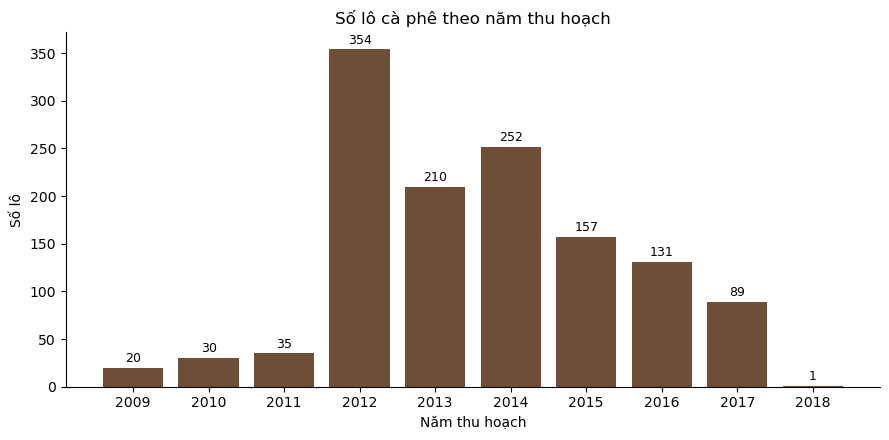

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(lots_per_year.index.astype(str), lots_per_year.values, color="#6F4E37")

ax.bar_label(bars, padding=2, fontsize=9)          # ghi số lô lên đầu mỗi cột
ax.set_title("Số lô cà phê theo năm thu hoạch")
ax.set_xlabel("Năm thu hoạch")
ax.set_ylabel("Số lô")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Nhận xét — giai đoạn:**
- Năm thu hoạch trải từ **2009 đến 2018**; có **60 lô (4,5%) thiếu năm thu hoạch**.
- Phần lớn lô tập trung trong giai đoạn **2012–2016** (chiếm khoảng 86,3% số lô có năm, tức 1.104/1.279 lô), nhiều nhất là năm **2012** với 354 lô.
- Các năm đầu (**2009–2011**: 20, 30, 35 lô) và năm cuối (**2018**) có rất ít lô (năm ít nhất chỉ 1 lô).
- Cột `Expiration` trải từ **09/04/2011 đến 19/01/2019**. Vì chứng nhận CQI có hạn 1 năm, các lô được chấm khoảng từ 04/2010 đến 01/2018; mốc cuối này khớp với thời điểm scrape tháng 01/2018 nêu ở phần (a).
- **Ảnh hưởng tới phân tích:** các năm quá ít lô không đủ để tính trung vị ổn định, nên câu Q4 (xu hướng theo năm) cần gộp hoặc loại các năm này và nêu rõ lý do; ngoài ra dữ liệu dừng ở 2018 nên không suy ra được xu hướng hiện tại.

#### (d) Độ phủ theo quốc gia: quốc gia nào chiếm nhiều lô, quốc gia nào quá ít?

In [22]:
# Độ phủ theo quốc gia
lots_per_country = df["Country.of.Origin"].value_counts()          # giảm dần sẵn

small = lots_per_country[lots_per_country < 10]
top3_share = lots_per_country.head(3).sum() / len(df)

print(f"Số quốc gia                 : {lots_per_country.size}")
print(f"Quốc gia có < 10 lô         : {small.size} nước, chiếm {small.sum()} lô ({small.sum() / len(df):.1%})")
print(f"Top 3 quốc gia chiếm        : {top3_share:.1%} tổng số lô")

lots_per_country.to_frame("Số lô").assign(**{"Tỷ lệ (%)": lambda t: (t["Số lô"] / len(df) * 100).round(2)})

Số quốc gia                 : 34
Quốc gia có < 10 lô         : 14 nước, chiếm 45 lô (3.4%)
Top 3 quốc gia chiếm        : 44.8% tổng số lô


,Số lô,Tỷ lệ (%)
Country.of.Origin,,
Mexico,236,17.63
Colombia,183,13.67
Guatemala,181,13.52
Brazil,132,9.86
United States,87,6.50
Taiwan,75,5.60
Honduras,53,3.96
Costa Rica,51,3.81
Ethiopia,44,3.29


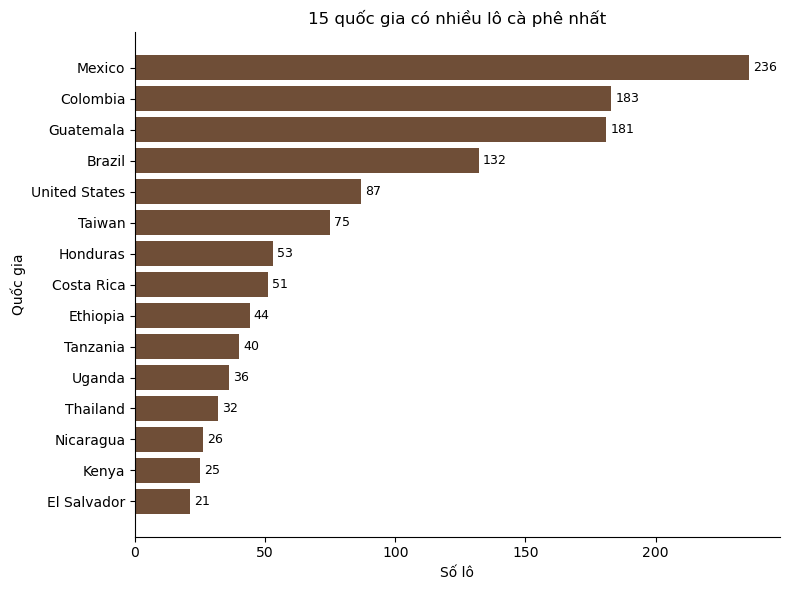

In [23]:
top15 = lots_per_country.head(15).sort_values()      # sắp tăng để cột dài nhất nằm trên cùng

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(top15.index, top15.values, color="#6F4E37")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("15 quốc gia có nhiều lô cà phê nhất")
ax.set_xlabel("Số lô")
ax.set_ylabel("Quốc gia")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#### (e) Hai file By_Country / By_Continent có phải nguồn dữ liệu độc lập không?

Giả thuyết: 2 file này là **bảng tổng hợp** tính từ file chính (`Rec_Cnt` = số lô, các cột `AVG_*` = trung bình). Kiểm tra bằng cách tự groupby file chính rồi so sánh.

In [24]:
for name, table in [("df_country", df_country), ("df_continent", df_continent)]:
    print(f"=== {name}: {table.shape} ===")
    print(list(table.columns))
    display(table.head())

=== df_country: (34, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Brazil,7.553106,7.573561,7.440530,7.511439,7.544545,7.531515,9.884924,9.853485,9.949394,0.082348,0.446970,0.128788,3.598485,132
1,Burundi,7.415000,7.460000,7.250000,7.415000,7.290000,7.415000,10.000000,10.000000,10.000000,0.060000,0.000000,0.000000,2.500000,2
2,China,7.641250,7.625625,7.484375,7.578125,7.573750,7.548125,9.958125,9.958125,9.916250,0.094375,0.500000,0.000000,4.000000,16
3,Colombia,7.653060,7.597104,7.524699,7.560000,7.609508,7.708415,9.934426,9.945355,9.952678,0.062022,0.207650,0.377049,1.939891,183
4,Costa Rica,7.671373,7.537255,7.534510,7.573922,7.537451,7.637255,9.856275,9.869216,9.908431,0.083333,0.117647,0.352941,2.823529,51


=== df_continent: (5, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Africa,7.759444,7.709444,7.623889,7.739074,7.680741,7.689938,9.954568,9.979321,9.813148,0.100926,0.166667,0.179012,3.734568,162
1,Asia,7.539121,7.499286,7.409231,7.478407,7.509066,7.473187,9.908187,9.970604,9.761813,0.079066,0.115385,0.752747,1.538462,182
2,North America,7.504346,7.445714,7.300767,7.496677,7.450977,7.432496,9.752632,9.734226,9.852992,0.096857,0.129323,0.566917,4.518797,665
3,Oceania,8.330000,8.420000,7.830000,8.330000,8.000000,8.250000,9.330000,9.330000,10.000000,0.120000,0.000000,0.000000,1.000000,1
4,South America,7.613415,7.589878,7.491585,7.545915,7.574756,7.629177,9.902866,9.894268,9.937470,0.070030,0.298780,0.301829,2.646341,328


In [25]:
# Groupby rồi so sánh
# 1. Dò tên cột trong df_country
key_col   = df_country.select_dtypes(exclude="number").columns[0]   # cột tên quốc gia
count_col = [c for c in df_country.columns if "cnt" in c.lower()][0] # cột Rec_Cnt
avg_cols  = [c for c in df_country.columns if c.upper().startswith("AVG")]

def match_raw_col(avg_col):
    """'AVG_Clean_Cup' -> 'Clean.Cup' (cột tương ứng trong df), không thấy thì trả None."""
    base = avg_col[4:].lower().replace("_", "").replace(".", "")
    for c in df.columns:
        if c.lower().replace(".", "").replace("_", "") == base:
            return c
    return None

avg_map = {a: match_raw_col(a) for a in avg_cols}
print("Cột khoá:", key_col, "| Cột đếm:", count_col)
print("Ánh xạ AVG -> cột gốc:", avg_map)

# 2. Tự tổng hợp từ file chính
raw_cols = [c for c in avg_map.values() if c is not None]
mine = (df.groupby("Country.of.Origin")
          .agg(n_lots=("REC_ID", "size"), **{f"mine_{c}": (c, "mean") for c in raw_cols})
          .reset_index())

# 3. Ghép với df_country để so sánh
compare = df_country.merge(mine, left_on=key_col, right_on="Country.of.Origin",
                           how="outer", indicator=True)
print(compare["_merge"].value_counts())
compare[[key_col, count_col, "n_lots"] + avg_cols[:2] + [f"mine_{c}" for c in raw_cols[:2]]].head(10)

Cột khoá: Country.of.Origin | Cột đếm: Rec_Cnt
Ánh xạ AVG -> cột gốc: {'AVG_Aroma': 'Aroma', 'AVG_Flavor': 'Flavor', 'AVG_Aftertaste': 'Aftertaste', 'AVG_Acidity': 'Acidity', 'AVG_Body': 'Body', 'AVG_Balance': 'Balance', 'AVG_Uniformity': 'Uniformity', 'AVG_Clean.Cup': 'Clean.Cup', 'AVG_Sweetness': 'Sweetness', 'AVG_Moisture': 'Moisture', 'AVG_Quakers': 'Quakers', 'AVG_Category.One.Defects': 'Category.One.Defects', 'AVG_Category.Two.Defects': 'Category.Two.Defects'}
_merge
both          34
left_only      0
right_only     0
Name: count, dtype: int64


,Country.of.Origin,Rec_Cnt,n_lots,AVG_Aroma,AVG_Flavor,mine_Aroma,mine_Flavor
0,Brazil,132,132,7.553106,7.573561,7.553106,7.573561
1,Burundi,2,2,7.415000,7.460000,7.415000,7.460000
2,China,16,16,7.641250,7.625625,7.641250,7.625625
3,Colombia,183,183,7.653060,7.597104,7.653060,7.597104
4,Costa Rica,51,51,7.671373,7.537255,7.671373,7.537255
5,Cote dIvoire,1,1,7.420000,7.250000,7.420000,7.250000
6,Ecuador,3,3,7.583333,7.640000,7.583333,7.640000
7,El Salvador,21,21,7.674762,7.654286,7.674762,7.654286
8,Ethiopia,44,44,7.896364,8.009091,7.896364,8.009091
9,Guatemala,181,181,7.544862,7.489006,7.544862,7.489006


In [26]:
# TEST
both = compare[compare["_merge"] == "both"]

# a) mọi quốc gia đều khớp tên
assert (compare["_merge"] == "both").all(), \
    f"Có quốc gia không khớp tên:\n{compare.loc[compare['_merge'] != 'both', [key_col, 'Country.of.Origin', '_merge']]}"

# b) số lô khớp Rec_Cnt
assert (both[count_col] == both["n_lots"]).all(), \
    f"Số lô lệch ở:\n{both.loc[both[count_col] != both['n_lots'], [key_col, count_col, 'n_lots']]}"

# c) trung bình khớp (làm tròn 2 chữ số vì file tổng hợp có thể đã làm tròn)
for avg_col, raw_col in avg_map.items():
    if raw_col is None:
        continue
    ok = np.allclose(both[avg_col], both[f"mine_{raw_col}"].round(2), atol=0.01)
    assert ok, f"{avg_col} không khớp với trung bình của {raw_col}"

print(f"df_country được tổng hợp từ df: khớp {len(both)} quốc gia, {len(avg_map)} cột AVG")

df_country được tổng hợp từ df: khớp 34 quốc gia, 13 cột AVG


**Kết luận — (e):**
- Cả 2 file `By_Country` (34 dòng) và `By_Continent` (5 dòng) đều là bảng tổng hợp tính ra từ file chính: `Rec_Cnt` khớp với số lô đếm được và 13 cột `AVG_*` khớp với trung bình tự tính cho cả 34 quốc gia và 5 châu lục. Sai lệch lớn nhất chỉ khoảng 10⁻¹⁵, là sai số dấu phẩy động, nên các giá trị trùng khớp hoàn toàn và file tổng hợp không hề làm tròn. Không có quốc gia hay châu lục nào lệch tên hoặc lệch số lô. *(Lưu ý: cột khoá của `By_Continent` bị đặt tên là `Country.of.Origin` dù chứa tên châu lục.)*
- Vì vậy 2 file này không chứa thông tin mới ngoài những gì một lệnh `groupby` trên file chính đã cho; chúng không phải nguồn dữ liệu độc lập.
- Về hình thức, nối với một bảng khác trong cùng bộ dữ liệu vẫn được tính là D1, nhưng phép nối như vậy không giúp trả lời được câu hỏi nào mới. Nhóm chọn nối với dữ liệu sản lượng FAOSTAT (câu Q5) vì nguồn này thực sự bổ sung thông tin bên ngoài (quy mô sản xuất của từng quốc gia) mà bộ CQI không có. File `By_Country` chỉ được giữ làm phương án dự phòng cho D1 và để đối chiếu.

#### (f) Hạn chế và thiên lệch đã biết

| Hạn chế | Bằng chứng từ dữ liệu | Ảnh hưởng tới phân tích |
|---|---|---|
| Thiên lệch chọn mẫu: chỉ có những lô được **gửi tới CQI để chấm**, không đại diện cho mọi lô cà phê trên thế giới | (lý luận, không có số) | Kết luận chỉ áp dụng cho các lô được gửi chấm |
| Mất cân bằng loài | Arabica 1.311 lô (97,91%) / Robusta 28 lô (2,09%) | Có thể chỉ phân tích Arabica |
| Độ phủ quốc gia không đều | 14/34 quốc gia có < 10 lô (tổng 45 lô, 3,4%), 6 nước chỉ có 1 lô; top 3 quốc gia (Mexico, Colombia, Guatemala) chiếm 44,8% | So sánh giữa các nước nhỏ không ổn định |
| Dữ liệu cũ, phân bố năm không đều | Năm thu hoạch 2009–2018, 60 lô (4,5%) thiếu năm; năm ít nhất (2018) chỉ có 1 lô, trong khi 2012 có 354 lô | Không suy ra xu hướng hiện tại |
| Thiếu một số biến quan trọng | Không có tổng điểm, điểm cupper, độ cao, giá | Nhóm phải tự tạo `total_9` |
| Dữ liệu scrape rồi chỉnh sửa, có thể có lỗi nhập liệu | Chi tiết ở 3.2 (giá trị 0, outlier) | Cần làm sạch trước khi phân tích |

**Collection method:**

- **Cách thu thập:** dữ liệu không do nhóm tự thu thập mà được scrape bằng script Python từ cơ sở dữ liệu công khai của CQI (01/2018). Bộ dữ liệu sau đó qua tay nhiều người trên Kaggle (Volpatto 2019, Boyar 2023) trước khi RealDealAdamP chỉnh sửa và công bố bản nhóm dùng (03/2024).
- **Quần thể:** 1.339 lô cà phê đã được Q Grader của CQI chấm điểm, đến từ 34 quốc gia thuộc 5 châu lục. Gần như toàn bộ là Arabica (97,91%); châu Mỹ chiếm hơn 74% số lô (Bắc Mỹ 49,66%, Nam Mỹ 24,50%).
- **Giai đoạn:** năm thu hoạch 2009–2018, tập trung ở 2012–2016 (86,3% số lô có năm); theo `Expiration`, các lô được chấm khoảng 04/2010–01/2018, khớp với thời điểm scrape. Hai file `By_Country`/`By_Continent` chỉ là bảng tổng hợp từ file chính nên không mở rộng thêm phạm vi dữ liệu.
- **Hạn chế:** mẫu chỉ gồm các lô được gửi tới CQI (thiên lệch chọn mẫu), mất cân bằng loài, độ phủ quốc gia rất lệch (14 nước có < 10 lô, top 3 nước chiếm 44,8%), dữ liệu đã cũ và thiếu tổng điểm, độ cao, giá. Vì vậy kết luận của nhóm chỉ áp dụng cho **các lô Arabica được chấm bởi CQI trong khoảng 2010–2018**, và các so sánh liên quan tới nước hoặc năm ít lô cần được gộp/loại và nêu rõ.

### 3.1.5. Motivation

Nhóm chọn bộ *Coffee Quality with Locations of Origin* vì 4 lý do:

**1. Chủ đề có ý nghĩa thực tế.** Điểm cupping của CQI được dùng làm thước đo chung khi mua bán cà phê nhân: lô đạt từ 80 điểm trở lên được xếp là cà phê đặc sản (specialty) và thường bán được giá cao hơn. Vì vậy câu hỏi *"điều gì gắn với một lô cà phê chất lượng cao?"* có người dùng cụ thể:
- **Nông hộ, hợp tác xã:** nên chọn giống, cách sơ chế nào, và cần kiểm soát độ ẩm, lỗi hạt ra sao trước khi gửi chấm.
- **Nhà nhập khẩu, nhà rang xay:** nên tìm nguồn hàng ở quốc gia, châu lục nào; quốc gia sản xuất nhiều có đồng nghĩa với chất lượng cao không.
- **Barista, người tiêu dùng:** điểm số ghi trên bao bì thực sự phản ánh những thuộc tính nào của tách cà phê.

**2. Dữ liệu phù hợp với yêu cầu đồ án.**
- *Dữ liệu thật:* 1.339 lô được Q Grader chấm, scrape từ cơ sở dữ liệu công khai của CQI (3.1.4a), không phải dữ liệu mô phỏng.
- *Đủ loại biến:* 13 biến số (9 thuộc tính cảm quan, độ ẩm, quakers, 2 loại lỗi hạt), các biến phân loại (loài, châu lục, 34 quốc gia, giống, màu hạt, cách sơ chế) và 2 biến thời gian (`Harvest.Year` 2009–2018, `Expiration`).
- *Đủ chất liệu cho các tiêu chí chiều sâu:* tự tạo biến `total_9` từ 9 thuộc tính cảm quan (D3); xu hướng theo năm (D2); kiểm tra một quan hệ có còn đúng trong từng quốc gia hoặc từng cách sơ chế không (D4); và có khoá quốc gia–năm để nối với dữ liệu sản lượng FAOSTAT (D1), nguồn bổ sung thông tin mà 2 file `By_Country`/`By_Continent` không có (3.1.4e).
- *Có bài toán ML tự nhiên:* dự đoán chất lượng của lô từ xuất xứ, cách sơ chế và các đặc tính vật lý của hạt.
- *Kích thước vừa phải:* 1.339 × 22, đủ để thống kê có ý nghĩa ở các nhóm lớn mà vẫn chạy nhanh. Các hạn chế (mất cân bằng loài, quốc gia ít lô, dữ liệu dừng ở 2018) đã được nhóm đo và ghi lại ở 3.1.4f để xử lý chủ động.

**3. Chưa bị khai thác quá nhiều.** Khác với Iris hay Titanic, bộ dữ liệu này ít được dùng làm ví dụ mẫu. TODO (Hiếu, theo `docs/related_work.md`): ghi số notebook công khai trên Kaggle và các notebook đó thường làm gì, để chỉ ra câu hỏi của nhóm khác họ ở đâu.

**4. Liên hệ với câu hỏi của nhóm.**
- **Q2 (ML):** 
- **Q4:** 
- **Q5:** 

### 3.1.6. Các file dữ liệu và cách nhóm sử dụng

In [27]:
# Tóm tắt 3 file
row_meaning = {
    MAIN_FILE.name:      "Một lô cà phê được CQI chấm điểm",
    COUNTRY_FILE.name:   "Một quốc gia (trung bình các chỉ số + số lô)",
    CONTINENT_FILE.name: "Một châu lục (trung bình các chỉ số + số lô)",
}
tables = {MAIN_FILE.name: df, COUNTRY_FILE.name: df_country, CONTINENT_FILE.name: df_continent}

files_summary = pd.DataFrame({
    "File":          list(tables.keys()),
    "Số dòng":       [t.shape[0] for t in tables.values()],
    "Số cột":        [t.shape[1] for t in tables.values()],
    "Một dòng là gì": [row_meaning[name] for name in tables],
})
files_summary

,File,Số dòng,Số cột,Một dòng là gì
0,Coffee_Qlty.csv,1339,22,Một lô cà phê được CQI chấm điểm
1,Coffee_Qlty_By_Country.csv,34,15,Một quốc gia (trung bình các chỉ số + số lô)
2,Coffee_Qlty_By_Continent.csv,5,15,Một châu lục (trung bình các chỉ số + số lô)


| File | Kích thước | Nội dung | Dùng cho |
|---|---|---|---|
| `Coffee_Qlty.csv` | 1.339 dòng × 22 cột | Mỗi dòng là một lô cà phê được CQI chấm điểm | File chính: exploration (3.2), Q1–Q6, mô hình ML |
| `Coffee_Qlty_By_Country.csv` | 34 dòng × 15 cột | Trung bình 13 chỉ số theo quốc gia (`AVG_*`) và số lô (`Rec_Cnt`) | Chỉ dùng để đối chiếu, phương án dự phòng cho D1 (đã kiểm chứng ở 3.1.4e) |
| `Coffee_Qlty_By_Continent.csv` | 5 dòng × 15 cột | Trung bình 13 chỉ số theo châu lục và số lô; cột khoá bị đặt tên `Country.of.Origin` dù chứa tên châu lục | Chỉ dùng để đối chiếu |


---
## 3.2. Data exploration


### 3.2.1. Overview
*(Đức Thịnh — `feat/eda-numeric`)*

### 3.2.2. Numerical columns
*(Đức Thịnh — `feat/eda-numeric`)*

### 3.2.3. Categorical columns
*(Tùng Hiếu — `feat/eda-categorical`)*

**Mục tiêu:** kiểm kê Species, Continent.of.Origin, Country.of.Origin, Variety, Color và Processing.Method trước khi chuẩn hoá, gộp nhóm hiếm hoặc lọc loài.

Mỗi dòng đầu vào được xem là một bản ghi lô cà phê. Phần này giữ nguyên tất cả dòng và nhãn. Ô trống được đọc thành giá trị thiếu; chuỗi `"None"` vẫn là một nhãn riêng cần xác minh.

#### a. Số nhãn, độ thiếu và mức tập trung

`n_unique_nonmissing` không tính giá trị thiếu. Các tỷ lệ trong bảng tổng quan đều có mẫu số là **toàn bộ số dòng đầu vào**. Độ tập trung được mô tả bằng tỷ lệ nhãn phổ biến nhất, chưa phải tiêu chuẩn tự động bỏ cột.

In [28]:
missing_columns = set(CAT_COLS) - set(df.columns)
if missing_columns:
    raise ValueError(f"Thiếu các cột bắt buộc: {sorted(missing_columns)}")
if df.empty:
    raise ValueError("Dữ liệu đầu vào không có dòng.")

n_rows = len(df)
summary_rows = []
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    top_label = counts.index[0] if not counts.empty else pd.NA
    top_count = int(counts.iloc[0]) if not counts.empty else 0
    summary_rows.append({
        "column": column,
        "n_unique_nonmissing": df[column].nunique(dropna=True),
        "n_missing": int(df[column].isna().sum()),
        "missing_pct_all": df[column].isna().mean() * 100,
        "top_label": top_label,
        "top_n": top_count,
        "top_pct_all": top_count / n_rows * 100,
    })
cat_summary = pd.DataFrame(summary_rows).set_index("column")
display(cat_summary.round(2))

,n_unique_nonmissing,n_missing,missing_pct_all,top_label,top_n,top_pct_all
column,,,,,,
Species,2,0,0.00,Arabica,1311,97.91
Continent.of.Origin,5,1,0.07,North America,665,49.66
Country.of.Origin,34,1,0.07,Mexico,236,17.63
Variety,29,226,16.88,Caturra,256,19.12
Color,4,218,16.28,Green,870,64.97
Processing.Method,5,170,12.70,Washed / Wet,815,60.87


#### b. Top 5 của từng cột

Mỗi bảng trình bày tối đa 5 **nhãn đã biết**, sắp theo số lô giảm dần. `pct_all` tính trên toàn bộ dòng, `pct_known` tính riêng các dòng không thiếu của cột. Tổng phần trăm top 5 có thể nhỏ hơn 100% vì còn nhãn khác và dữ liệu thiếu. Số thiếu được báo riêng trong bảng tổng quan.

In [29]:
top5_tables = {}
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    known_n = int(df[column].notna().sum())
    table = counts.head(5).rename_axis("label").reset_index(name="n_lots")
    table.insert(0, "rank", range(1, len(table) + 1))
    table["pct_all"] = table["n_lots"] / n_rows * 100
    table["pct_known"] = table["n_lots"] / known_n * 100 if known_n else float("nan")
    top5_tables[column] = table
    print(f"{column} — đã biết: {known_n:,}; thiếu: {n_rows - known_n:,}")
    display(table.round(2))

Species — đã biết: 1,339; thiếu: 0


,rank,label,n_lots,pct_all,pct_known
0,1,Arabica,1311,97.91,97.91
1,2,Robusta,28,2.09,2.09


Continent.of.Origin — đã biết: 1,338; thiếu: 1


,rank,label,n_lots,pct_all,pct_known
0,1,North America,665,49.66,49.70
1,2,South America,328,24.50,24.51
2,3,Asia,182,13.59,13.60
3,4,Africa,162,12.10,12.11
4,5,Oceania,1,0.07,0.07


Country.of.Origin — đã biết: 1,338; thiếu: 1


,rank,label,n_lots,pct_all,pct_known
0,1,Mexico,236,17.63,17.64
1,2,Colombia,183,13.67,13.68
2,3,Guatemala,181,13.52,13.53
3,4,Brazil,132,9.86,9.87
4,5,United States,87,6.50,6.50


... (2 outputs left out)

Color — đã biết: 1,121; thiếu: 218


,rank,label,n_lots,pct_all,pct_known
0,1,Green,870,64.97,77.61
1,2,Bluish-Green,114,8.51,10.17
2,3,Blue-Green,85,6.35,7.58
3,4,None,52,3.88,4.64


Processing.Method — đã biết: 1,169; thiếu: 170


,rank,label,n_lots,pct_all,pct_known
0,1,Washed / Wet,815,60.87,69.72
1,2,Natural / Dry,258,19.27,22.07
2,3,Semi-washed / Semi-pulped,56,4.18,4.79
3,4,Other,26,1.94,2.22
4,5,Pulped natural / honey,14,1.05,1.20


#### c. Cơ cấu Species và phương án phân tích

Biểu đồ dùng toàn bộ dữ liệu đầu vào để đánh giá mức mất cân bằng. Đây là bằng chứng để thảo luận phạm vi phân tích; phần này **chưa loại Robusta**. Nếu cần nhận xét về khác biệt quy trình/thang chấm giữa hai loài, phải bổ sung nguồn chuyên môn trước khi dùng làm lý do lọc.

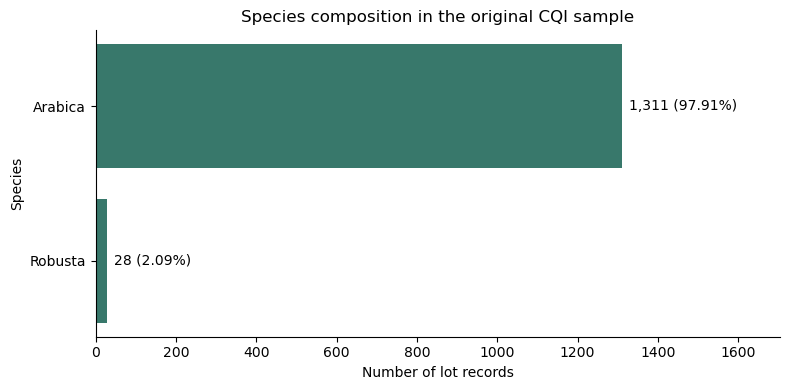

In [30]:
species_counts = df["Species"].fillna("Missing").value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(species_counts.index, species_counts.values, color="#38786b")
ax.invert_yaxis()
ax.set_title("Species composition in the original CQI sample")
ax.set_xlabel("Number of lot records")
ax.set_ylabel("Species")
ax.set_xlim(0, species_counts.max() * 1.3)
ax.bar_label(bars, labels=[f"{n:,} ({n / n_rows:.2%})" for n in species_counts], padding=5)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

#### d. Độ tập trung và các nhóm ít lô

Bảng dưới bổ sung tỷ lệ nhãn đứng đầu trên các lô có nhãn và số nhóm dưới 20 lô.

In [31]:
balance_rows = []
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    known_n = int(counts.sum())
    balance_rows.append({
        "column": column,
        "top_pct_known": counts.iloc[0] / known_n * 100 if known_n else float("nan"),
        "n_categories_lt20": int(counts.lt(20).sum()),
        "n_lots_in_categories_lt20": int(counts[counts.lt(20)].sum()),
    })
display(pd.DataFrame(balance_rows).set_index("column").round(2))

arabica_mask = df["Species"].eq("Arabica")
scope_options = pd.DataFrame([
    {"scope": "All species (current)", "n_lots": n_rows, "retained_pct": 100.0},
    {"scope": "Arabica only (proposal)", "n_lots": int(arabica_mask.sum()),
     "retained_pct": arabica_mask.mean() * 100},
])
display(scope_options.round(2))
print("Chưa áp dụng bộ lọc Species. Cần nhóm thống nhất phạm vi trước khi lọc.")

,top_pct_known,n_categories_lt20,n_lots_in_categories_lt20
column,,,
Species,97.91,0,0
Continent.of.Origin,49.70,1,1
Country.of.Origin,17.64,18,96
Variety,23.00,20,104
Color,77.61,0,0
Processing.Method,69.72,1,14


,scope,n_lots,retained_pct
0,All species (current),1339,100.00
1,Arabica only (proposal),1311,97.91


Chưa áp dụng bộ lọc Species. Cần nhóm thống nhất phạm vi trước khi lọc.


#### e. Kiểm tra tính nhất quán

Các kiểm tra sau xác nhận số đếm, mẫu số và nhãn `None` không bị mất do cách đọc file. Không có thao tác loại dòng trong mục này.

In [32]:
assert len(df) == n_rows
for column in CAT_COLS:
    assert df[column].value_counts().sum() + df[column].isna().sum() == n_rows
    table = top5_tables[column]
    assert len(table) <= 5
    assert table["n_lots"].sum() <= df[column].notna().sum()
    assert table["pct_all"].between(0, 100).all()
print(f"Đã kiểm tra {len(CAT_COLS)} cột; số dòng trước/sau: {n_rows:,}/{len(df):,}.")
print("Color literal 'None':", int(df["Color"].eq("None").sum()))

Đã kiểm tra 6 cột; số dòng trước/sau: 1,339/1,339.
Color literal 'None': 52


#### f. Chuẩn hoá nhãn — Bước 2

Quy trình: tạo bản sao `df_labels` từ `df`; chỉ sửa 6 cột phân loại bằng `src/labels.py`. Cắt và thu gọn khoảng trắng, đưa về chữ thường bằng `casefold`, rồi áp dụng ánh xạ quốc gia tường minh. Không lọc dòng, không sửa cột số, không tự gộp các tên giống cà phê, màu sắc hoặc cách sơ chế chỉ vì cách viết gần nhau.

Giữ `df` để đối chiếu. Literal `Color="None"` thành nhãn `"none"`, vẫn khác giá trị thiếu. `Other` thành `other`, vẫn khác nhóm do thuật toán gộp. Bảng ánh xạ quốc gia ở đây chưa phải ánh xạ sang tên FAOSTAT; không tự gộp Hawaii hoặc vùng lãnh thổ vào quốc gia.

Bảng trước/sau tập trung vào Country, Variety, Processing theo phân công, đồng thời kiểm tra số thiếu và số dòng. Việc đổi cách viết không nhất thiết làm giảm số nhãn.

In [33]:
# Mọi lần chạy lại đều bắt đầu từ dữ liệu gốc.
df_labels = normalize_labels(df)
REVIEW_COLS = ["Country.of.Origin", "Variety", "Processing.Method"]
normalization_summary = pd.DataFrame([
    {
        "column": column,
        "unique_before": df[column].nunique(dropna=True),
        "unique_after": df_labels[column].nunique(dropna=True),
        "missing_before": int(df[column].isna().sum()),
        "missing_after": int(df_labels[column].isna().sum()),
        "changed_rows": int(
            df[column].astype("string").fillna("<MISSING>")
            .ne(df_labels[column].fillna("<MISSING>")).sum()
        ),
    }
    for column in REVIEW_COLS
]).set_index("column")
display(normalization_summary)
print(f"Chuẩn hoá: {len(df):,} → {len(df_labels):,} dòng; không lọc dòng.")

,unique_before,unique_after,missing_before,missing_after,changed_rows
column,,,,,
Country.of.Origin,34,34,1,1,1338
Variety,29,29,226,226,1113
Processing.Method,5,5,170,170,1169


Chuẩn hoá: 1,339 → 1,339 dòng; không lọc dòng.


**Kiểm toán nhãn:** bảng dưới liệt kê từng nhãn thực tế trước/sau cùng số lô, kể cả trường hợp không thay đổi. Bảng alias chỉ hiện các quy tắc thực sự khớp trong bản dữ liệu đang đọc; không coi quy tắc chưa xuất hiện là lỗi đã quan sát.

In [34]:
label_audits = {}
for column in REVIEW_COLS:
    pairs = pd.DataFrame({
        "before": df[column].astype("string"),
        "after": df_labels[column],
    })
    audit = pairs.groupby(["before", "after"], dropna=False).size().reset_index(name="n_lots")
    audit = audit.sort_values(["n_lots", "before"], ascending=[False, True]).reset_index(drop=True)
    label_audits[column] = audit
    print(column)
    display(audit)

country_base = (df["Country.of.Origin"].astype("string").str.strip()
                .str.replace(r"\s+", " ", regex=True).str.casefold())
alias_usage = pd.DataFrame([
    {"from": old, "to": new, "n_lots": int(country_base.eq(old).sum())}
    for old, new in COUNTRY_ALIASES.items()
    if country_base.eq(old).any()
])
print("Alias quốc gia thực sự được áp dụng:")
display(alias_usage)

Country.of.Origin


,before,after,n_lots
0,Mexico,mexico,236
1,Colombia,colombia,183
2,Guatemala,guatemala,181
3,Brazil,brazil,132
4,United States,united states,87
5,Taiwan,taiwan,75
6,Honduras,honduras,53
7,Costa Rica,costa rica,51
8,Ethiopia,ethiopia,44
9,Tanzania,tanzania,40


Variety


,before,after,n_lots
0,Caturra,caturra,256
1,Bourbon,bourbon,226
2,<NA>,<NA>,226
3,Typica,typica,211
4,Other,other,110
5,Catuai,catuai,74
6,Hawaiian Kona,hawaiian kona,44
7,Yellow Bourbon,yellow bourbon,35
8,Mundo Novo,mundo novo,33
9,Catimor,catimor,20


Processing.Method


,before,after,n_lots
0,Washed / Wet,washed / wet,815
1,Natural / Dry,natural / dry,258
2,<NA>,<NA>,170
3,Semi-washed / Semi-pulped,semi-washed / semi-pulped,56
4,Other,other,26
5,Pulped natural / honey,pulped natural / honey,14


Alias quốc gia thực sự được áp dụng:


,from,to,n_lots
0,cote divoire,cote d'ivoire,1


#### g. Gộp nhãn hiếm để trình bày

Theo kế hoạch tuần 1, dùng `min_n=20`: nhãn có **ít hơn 20 lô** trong toàn bộ mẫu hiện tại được gộp; nhãn có đúng 20 lô được giữ. Đây là ngưỡng thực hành nhằm giảm các nhóm quá nhỏ khi trình bày, không phải bằng chứng rằng mọi median từ 20 lô trở lên đều ổn định.

Tạo các cột mới có hậu tố `__grouped` trong `df_grouped` cho Country, Variety, Processing. Nhãn chuẩn hoá vẫn được giữ để nối FAOSTAT và phân tích chi tiết. Không dùng quốc gia đã gộp làm khoá nối. Nhãn thiếu giữ nguyên; `Other (rare)` chỉ các nhóm do thuật toán gộp, khác nhãn `other` có sẵn.

Không áp dụng gộp cho Species, Continent hoặc Color ở bước này. Nếu câu hỏi tập trung vào một nhóm hiếm (ví dụ honey processing), phải dùng cột chưa gộp hoặc xem xét quy tắc riêng. Nếu sau này lọc Arabica, cần tính lại tần suất trên mẫu mới. Nếu dùng cho ML, quy tắc tần suất phải được học riêng trên train.

In [35]:
MIN_N = 20
RARE_LABEL = "Other (rare)"
df_grouped = df_labels.copy(deep=True)
rare_summaries = []
rare_audits = {}
for column in REVIEW_COLS:
    counts = df_labels[column].value_counts(dropna=True)
    rare_counts = counts[counts.lt(MIN_N)]
    grouped_column = column + "__grouped"
    df_grouped[grouped_column] = group_rare(df_labels[column], min_n=MIN_N, other=RARE_LABEL)
    audit = rare_counts.rename_axis("original_label").reset_index(name="n_lots")
    audit["grouped_label"] = RARE_LABEL
    audit["pct_all"] = audit["n_lots"] / len(df_labels) * 100
    rare_audits[column] = audit
    rare_summaries.append({
        "column": column,
        "unique_before": df_labels[column].nunique(dropna=True),
        "unique_after": df_grouped[grouped_column].nunique(dropna=True),
        "n_rare_categories": len(rare_counts),
        "n_grouped_lots": int(rare_counts.sum()),
        "grouped_pct_all": rare_counts.sum() / len(df_labels) * 100,
        "missing_after": int(df_grouped[grouped_column].isna().sum()),
    })
    print(f"{column} — các nhãn được gộp:")
    display(audit.round(2))
rare_summary = pd.DataFrame(rare_summaries).set_index("column")
display(rare_summary.round(2))
print(f"Gộp nhóm: {len(df_labels):,} → {len(df_grouped):,} dòng; chỉ thêm 3 cột trình bày.")

Country.of.Origin — các nhãn được gộp:


,original_label,n_lots,grouped_label,pct_all
0,china,16,Other (rare),1.19
1,india,14,Other (rare),1.05
2,malawi,11,Other (rare),0.82
3,peru,10,Other (rare),0.75
4,vietnam,8,Other (rare),0.6
5,myanmar,8,Other (rare),0.6
6,haiti,6,Other (rare),0.45
7,philippines,5,Other (rare),0.37
8,panama,4,Other (rare),0.3
9,ecuador,3,Other (rare),0.22


Variety — các nhãn được gộp:


,original_label,n_lots,grouped_label,pct_all
0,sl14,17,Other (rare),1.27
1,sl28,15,Other (rare),1.12
2,pacas,13,Other (rare),0.97
3,gesha,12,Other (rare),0.9
4,pacamara,8,Other (rare),0.6
5,sl34,8,Other (rare),0.6
6,arusha,6,Other (rare),0.45
7,peaberry,5,Other (rare),0.37
8,sumatra,3,Other (rare),0.22
9,mandheling,3,Other (rare),0.22


Processing.Method — các nhãn được gộp:


,original_label,n_lots,grouped_label,pct_all
0,pulped natural / honey,14,Other (rare),1.05


,unique_before,unique_after,n_rare_categories,n_grouped_lots,grouped_pct_all,missing_after
column,,,,,,
Country.of.Origin,34,17,18,96,7.17,1
Variety,29,10,20,104,7.77,226
Processing.Method,5,5,1,14,1.05,170


Gộp nhóm: 1,339 → 1,339 dòng; chỉ thêm 3 cột trình bày.


#### h. Kiểm tra ngưỡng và bảo toàn dữ liệu

So sánh 10, 20 và 30 để thấy mức mất chi tiết do ngưỡng gộp. Bảng này chỉ đánh giá tác động lên cơ cấu nhóm, chưa chứng minh một kết luận nghiên cứu bền vững. Trước khi dùng cột gộp cho câu hỏi cụ thể, thành viên cần giải thích lựa chọn và kiểm tra kết luận với cột chưa gộp.

Các kiểm tra bảo toàn xác nhận: số dòng/index, các cột không thuộc phạm vi chuẩn hoá, vị trí thiếu hiện tại và nhãn `none`/`other` không bị đánh đồng với nhóm hiếm.

In [36]:
threshold_rows = []
for column in REVIEW_COLS:
    counts = df_labels[column].value_counts(dropna=True)
    for threshold in [10, 20, 30]:
        grouped = group_rare(df_labels[column], min_n=threshold, other=RARE_LABEL)
        threshold_rows.append({
            "column": column, "min_n": threshold,
            "n_rare_categories": int(counts.lt(threshold).sum()),
            "n_grouped_lots": int(counts[counts.lt(threshold)].sum()),
            "n_categories_after": grouped.nunique(dropna=True),
        })
display(pd.DataFrame(threshold_rows))

untouched_cols = [c for c in df.columns if c not in CAT_COLS]
pd.testing.assert_frame_equal(df_labels[untouched_cols], df[untouched_cols])
pd.testing.assert_index_equal(df_labels.index, df.index)
pd.testing.assert_frame_equal(normalize_labels(df_labels), df_labels)
assert len(df) == len(df_labels) == len(df_grouped)
for column in CAT_COLS:
    assert df[column].isna().equals(df_labels[column].isna())
for column in REVIEW_COLS:
    original = df_labels[column]
    grouped = df_grouped[column + "__grouped"]
    assert original.isna().equals(grouped.isna())
    pd.testing.assert_series_equal(df_grouped[column], original)
    assert grouped.eq(RARE_LABEL).sum() == rare_summary.loc[column, "n_grouped_lots"]
    # Nhãn Other có sẵn trong mẫu hiện tại đều >=20, nên được giữ riêng.
    assert grouped[original.eq("other").fillna(False)].eq("other").all()
assert df_labels["Color"].eq("none").sum() == df["Color"].eq("None").sum()
print("Đạt: không mất dòng, giữ cột gốc và giá trị thiếu; chuẩn hoá có tính lặp ổn định.")

,column,min_n,n_rare_categories,n_grouped_lots,n_categories_after
0,Country.of.Origin,10,14,45,21
1,Country.of.Origin,20,18,96,17
2,Country.of.Origin,30,22,188,13
3,Variety,10,16,47,14
4,Variety,20,20,104,10
5,Variety,30,21,124,9
6,Processing.Method,10,0,0,5
7,Processing.Method,20,1,14,5
8,Processing.Method,30,2,40,4


Đạt: không mất dòng, giữ cột gốc và giá trị thiếu; chuẩn hoá có tính lặp ổn định.


#### Nhận xét — Categorical columns

- **Species và xuất xứ:** Biểu đồ cho thấy Arabica chiếm 1.311/1.339 lô (97,91%), còn Robusta có 28 lô (2,09%). Nếu giới hạn EDA gốc ở Arabica, phạm vi kết luận sẽ là 1.311 lô Arabica. North America có 665 lô (49,66%), trong khi Oceania chỉ có 1 lô. Mexico, Colombia và Guatemala có tổng cộng 600 lô (44,81% mẫu). Mẫu này tập trung vào Arabica và một số nước có nhiều lô được CQI chấm điểm. Vì vậy, kết quả tính trên toàn bộ mẫu chịu ảnh hưởng nhiều hơn từ các nhóm đông lô. Riêng Oceania chỉ có một lô, nên không đủ dữ liệu để so sánh châu lục này với North America hay South America.
- **Nhãn phổ biến và giá trị thiếu:** Trong 1.339 lô, có 256 lô Caturra, chiếm 19,12%. Khi chỉ tính 1.113 lô có nhãn `Variety`, tỷ lệ này là 23,00%. Tương tự, 870 lô Green chiếm 64,97% trong 1.339 lô và 77,61% trong 1.121 lô có nhãn `Color`. Với `Processing.Method`, 815 lô Washed / Wet chiếm 60,87% trong toàn bộ 1.339 lô. Nếu bỏ 170 lô thiếu nhãn sơ chế, mẫu số còn 1.169 lô và tỷ lệ Washed / Wet là 69,72%. `Color` có 218 ô thiếu. Ngoài ra, 52 lô mang nhãn `None` được ghi sẵn trong CSV. Bảng giữ chúng thành một nhóm riêng, nên 1.121 lô có nhãn `Color` bao gồm cả 52 lô này.
- **Chuẩn hoá:** Sau chuẩn hoá, số nhãn của `Country.of.Origin`, `Variety` và `Processing.Method` vẫn lần lượt là 34, 29 và 5. Thay đổi chủ yếu nằm ở cách viết hoa/thường. Alias `Cote dIvoire` → `cote d'ivoire` áp dụng cho một lô. Số dòng và số ô thiếu giữ nguyên. Như vậy, bước này thống nhất cách viết để dùng nhãn nhất quán ở các bảng sau, đồng thời giữ nguyên cơ cấu nhóm của mẫu.
- **Gộp nhóm hiếm:** Ngưỡng dưới 20 lô đưa 96 lô thuộc 18 nhãn quốc gia và 104 lô thuộc 20 nhãn giống vào `Other (rare)`. Số nhãn sau gộp còn 17 và 10. Với `Processing.Method`, chỉ 14 lô Pulped natural / honey được đổi thành `Other (rare)`, nên số nhãn vẫn là 5. Nhóm `Other` gốc vẫn riêng ở ngưỡng 20. Tăng ngưỡng từ 10 lên 30 làm số lô gộp theo quốc gia tăng từ 45 lên 188 và theo giống từ 47 lên 124. Với Q5, dùng nhãn quốc gia chưa gộp để nối FAOSTAT và giữ riêng các nhóm ít lô khi chúng thuộc phạm vi câu hỏi.

### 3.2.4. Missing data
*(Đức Thịnh — `feat/eda-numeric`)*

### 3.2.5. Relationships
*(Tùng Hiếu — `feat/eda-categorical`)*

#### Mẫu phân tích và `total_9`

`df_eda` là bản sao có `total_9` của `df`, bỏ riêng `REC_ID=1310` theo quy ước nhóm vì cả 9 điểm cảm quan đều bằng 0. Mẫu gồm cả Arabica và Robusta. Hai dòng 721 và 742 cùng các giá trị ngoại lệ còn lại được giữ trong EDA.

`total_9` là tổng 9 thuộc tính trong `SCORE_COLS` (thang 0–90). Một thuộc tính thiếu làm tổng điểm thiếu.

In [37]:
df_eda = add_total_score(df).loc[lambda rows: rows["REC_ID"].ne(1310)].copy()
physical_cols = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]
relationship_cols = [*SCORE_COLS, *physical_cols, "total_9"]
print(f"Số lô trước và sau khi lọc: {len(df):,} → {len(df_eda):,}")
display(df_eda["Species"].value_counts(dropna=False).rename("n_lots").to_frame())
display(pd.DataFrame({
    "missing": df_eda[physical_cols].isna().sum(),
    "zero": df_eda[physical_cols].eq(0).sum(),
}))

Số lô trước và sau khi lọc: 1,339 → 1,338


,n_lots
Species,
Arabica,1310
Robusta,28


,missing,zero
Moisture,0,264
Quakers,0,1244
Category.One.Defects,0,1136
Category.Two.Defects,0,373


#### Correlation heatmaps và scatter plots

Tính Pearson và Spearman trên các quan sát có đủ dữ liệu cho từng cặp biến. Bảng `pairwise_n` cho biết mẫu số. `total_9` chứa chính các điểm thành phần, nên khi diễn giải cần xét mối liên hệ do công thức tổng tạo ra.

,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects,total_9
Aroma,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Flavor,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Aftertaste,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Acidity,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Body,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Balance,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Uniformity,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Clean.Cup,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Sweetness,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Moisture,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338


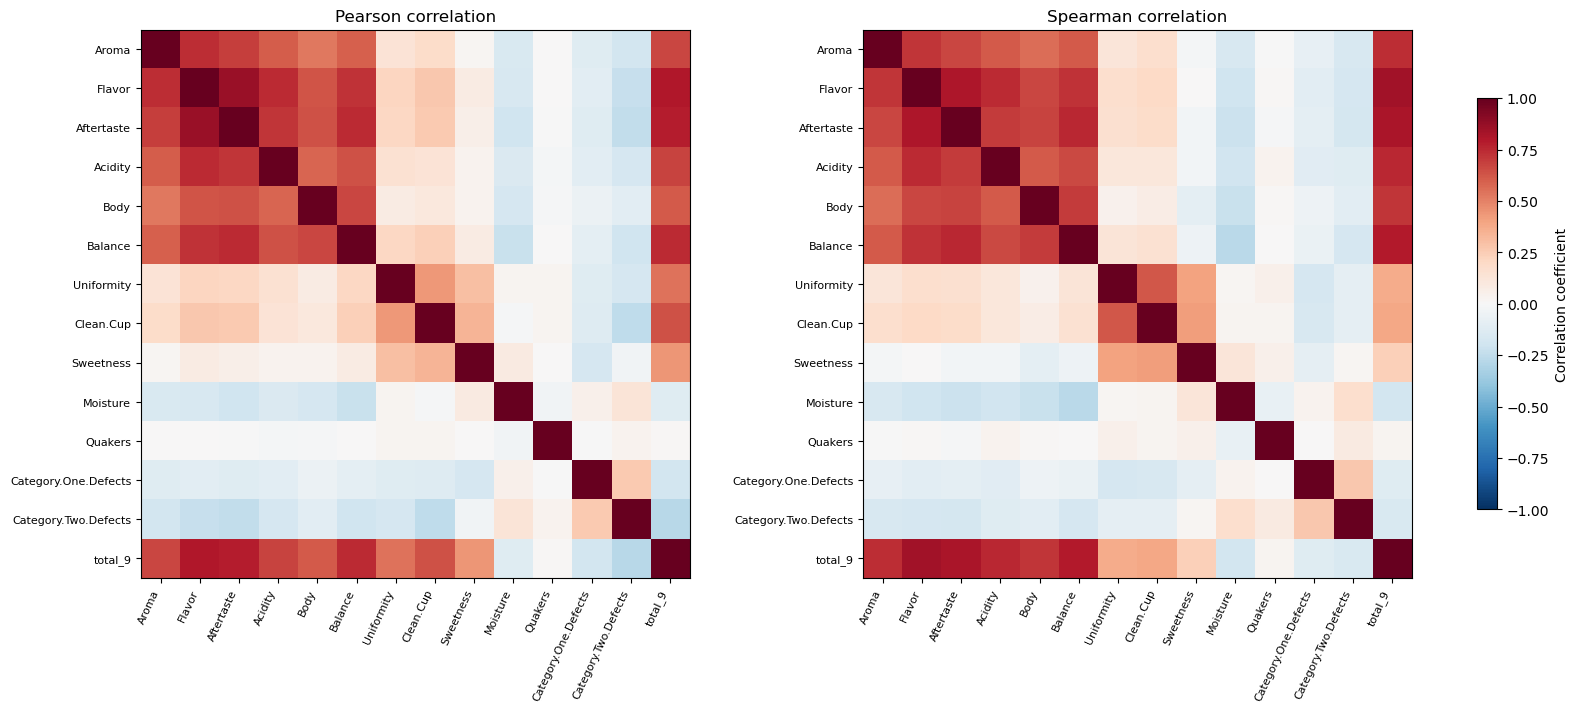

,variable_1,variable_2,n_lots,pearson,spearman
13,Flavor,Aftertaste,1338,0.860,0.809
24,Flavor,total_9,1338,0.798,0.836
35,Aftertaste,total_9,1338,0.784,0.815
14,Flavor,Acidity,1338,0.746,0.744
27,Aftertaste,Balance,1338,0.746,0.753
62,Balance,total_9,1338,0.743,0.791
0,Aroma,Flavor,1338,0.740,0.715
16,Flavor,Balance,1338,0.720,0.725
25,Aftertaste,Acidity,1338,0.716,0.697
1,Aroma,Aftertaste,1338,0.694,0.668


In [38]:
relationship_numeric = df_eda[relationship_cols]
available = relationship_numeric.notna().astype(int)
pairwise_n = available.T @ available
correlations = {
    method: relationship_numeric.corr(method=method)
    for method in ("pearson", "spearman")
}
display(pairwise_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained")
for ax, (method, matrix) in zip(axes, correlations.items()):
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=8)
    ax.set_title(f"{method.title()} correlation")
fig.colorbar(image, ax=axes, shrink=0.75, label="Correlation coefficient")
plt.show()

row_idx, col_idx = np.triu_indices(len(relationship_cols), k=1)
correlation_pairs = pd.DataFrame({
    "variable_1": relationship_numeric.columns[row_idx],
    "variable_2": relationship_numeric.columns[col_idx],
    "n_lots": pairwise_n.to_numpy()[row_idx, col_idx],
    **{method: matrix.to_numpy()[row_idx, col_idx] for method, matrix in correlations.items()},
})
display(correlation_pairs.sort_values("pearson", key=lambda values: values.abs(), ascending=False).head(10).round(3))

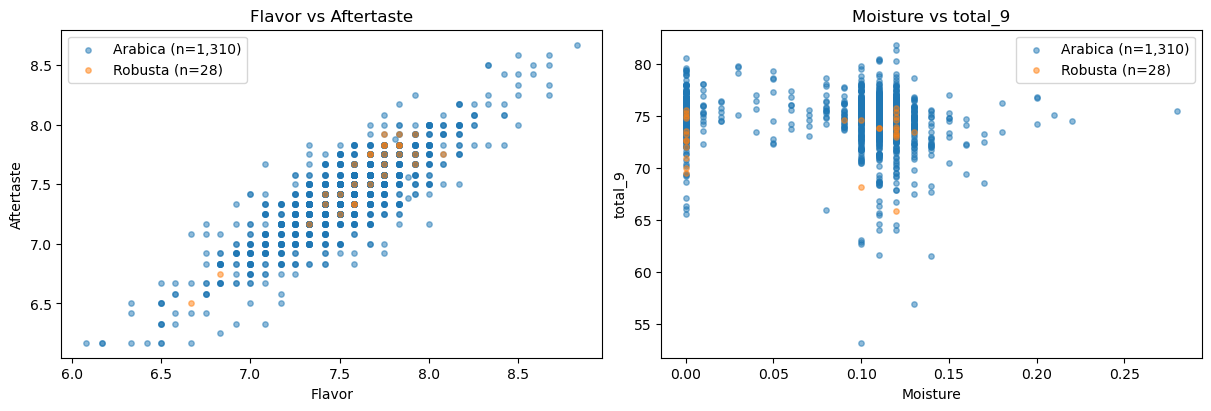

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, (x, y) in zip(axes, [("Flavor", "Aftertaste"), ("Moisture", "total_9")]):
    for species, rows in df_eda.groupby("Species"):
        points = rows[[x, y]].dropna()
        ax.scatter(points[x], points[y], s=15, alpha=0.5, label=f"{species} (n={len(points):,})")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}")
    ax.legend()
plt.show()

#### `Species` và `Country.of.Origin`

So sánh số lô và median `total_9` theo `Species`. Bảng quốc gia dùng tên chưa gộp và chỉ giữ các quốc gia có ít nhất 20 lô có `total_9` hợp lệ.

In [40]:
valid_score_lots = df_eda.dropna(subset=["total_9"])
species_score_summary = valid_score_lots.groupby("Species")["total_9"].agg(
    n_lots="size", median_total_9="median",
)
country_score_summary = (
    valid_score_lots.groupby("Country.of.Origin")["total_9"]
    .agg(n_lots="size", median_total_9="median")
    .query("n_lots >= 20")
    .sort_values("median_total_9", ascending=False)
)
display(species_score_summary.round(2))
display(country_score_summary.round(2))

,n_lots,median_total_9
Species,,
Arabica,1310,75.00
Robusta,28,73.66


,n_lots,median_total_9
Country.of.Origin,,
Ethiopia,44,77.25
Kenya,25,76.83
Colombia,183,75.68
Uganda,36,75.55
El Salvador,21,75.50
Indonesia,20,75.37
Costa Rica,51,75.34
Thailand,32,75.13
Guatemala,181,75.07


#### Crosstab `Continent.of.Origin` × `Processing.Method`

Bảng số lô dùng nhãn hiển thị `Unknown` cho giá trị thiếu. Bảng tỷ lệ theo hàng chỉ dùng lô có đủ cả hai nhãn. Cột `n_known` là mẫu số của từng châu lục.

In [41]:
continent_col = "Continent.of.Origin"
method_col = "Processing.Method"
crosstab_counts = pd.crosstab(
    df_eda[continent_col].fillna("Unknown"),
    df_eda[method_col].fillna("Unknown"),
    margins=True,
    margins_name="Total",
)
known_processing = df_eda.dropna(subset=[continent_col, method_col])
crosstab_pct = pd.crosstab(
    known_processing[continent_col], known_processing[method_col], normalize="index",
).mul(100)
crosstab_pct.insert(0, "n_known", known_processing.groupby(continent_col).size())
print(f"Số lô đủ cả hai nhãn: {len(known_processing):,}")
display(crosstab_counts)
display(crosstab_pct.round(2))

Số lô đủ cả hai nhãn: 1,169


Processing.Method,Natural / Dry,Other,Pulped natural / honey,Semi-washed / Semi-pulped,Unknown,Washed / Wet,Total
Continent.of.Origin,,,,,,,
Africa,27,0,0,2,33,100,162
Asia,32,17,5,14,25,89,182
North America,91,8,2,16,57,490,664
Oceania,0,0,0,0,0,1,1
South America,108,1,7,24,53,135,328
Unknown,0,0,0,0,1,0,1
Total,258,26,14,56,169,815,1338


Processing.Method,n_known,Natural / Dry,Other,Pulped natural / honey,Semi-washed / Semi-pulped,Washed / Wet
Continent.of.Origin,,,,,,
Africa,129,20.93,0.00,0.00,1.55,77.52
Asia,157,20.38,10.83,3.18,8.92,56.69
North America,607,14.99,1.32,0.33,2.64,80.72
Oceania,1,0.00,0.00,0.00,0.00,100.00
South America,275,39.27,0.36,2.55,8.73,49.09


In [42]:
# TEST
assert set(df["REC_ID"]) - set(df_eda["REC_ID"]) == {1310}
assert len(df_eda) == len(df) - 1
assert "total_9" not in df.columns
assert {721, 742}.issubset(set(df_eda["REC_ID"]))
assert df_eda["total_9"].isna().equals(df_eda[SCORE_COLS].isna().any(axis=1))
assert crosstab_counts.loc["Total", "Total"] == len(df_eda)
assert crosstab_pct["n_known"].sum() == len(known_processing)
assert np.allclose(crosstab_pct.drop(columns="n_known").sum(axis=1), 100)
assert country_score_summary["n_lots"].ge(20).all()
print("Relationship checks passed")

Relationship checks passed


#### Nhận xét — Relationships

- **Correlation heatmaps:** Các cặp trong hai ma trận đều có 1.338 lô. `Flavor` và `Aftertaste` có tương quan dương mạnh theo cả Pearson là 0,860 và Spearman là 0,809. Scatter plot cho thấy dải điểm đi lên rõ. `Clean.Cup` và `total_9` có chênh lệch tuyệt đối giữa hai hệ số khoảng 0,251, lớn nhất trong các cặp gồm hai biến khác nhau. Mức chênh này cho thấy độ mạnh của liên hệ thay đổi tùy cách đo. Vì `Clean.Cup` là một phần của `total_9`, tương quan giữa chúng có sẵn một phần từ công thức tính tổng.
- **`Moisture` và `total_9`:** Scatter plot cho thấy `total_9` phân tán rộng ở cùng mức `Moisture`, đặc biệt ở vùng 0,10–0,13. Có một cụm dọc tại 0 với 264 lô. Pearson khoảng −0,121 và Spearman khoảng −0,185, cho thấy liên hệ âm yếu trong mẫu gộp. Cụm 264 lô ở mức 0 chiếm gần một phần năm mẫu. Nếu các số 0 là giá trị quy ước thay cho số đo còn thiếu, hệ số hiện tại có thể thay đổi khi xử lý lại nhóm này.
- **`Species` và điểm tổng:** Median `total_9` của Arabica là 75,00 trên 1.310 lô, còn Robusta là 73,66 trên 28 lô. Chênh lệch mô tả khoảng 1,34 điểm. Do Arabica chiếm gần 98% mẫu Relationships, kết quả gộp chủ yếu phản ánh các lô Arabica. Với 28 lô, median Robusta dựa trên ít quan sát hơn nhiều so với Arabica. Chênh lệch 1,34 điểm vì vậy được trình bày như một so sánh mô tả trong mẫu.
- **Crosstab:** Bảng tỷ lệ dùng 1.169 lô có đủ `Continent.of.Origin` và `Processing.Method`. Trong số các lô có đủ nhãn, Washed / Wet chiếm 80,72% ở North America, tương ứng 490 trên 607 lô, và 77,52% ở Africa, tương ứng 100 trên 129 lô. South America có tỷ lệ Natural / Dry là 39,27%, tương ứng 108 trên 275 lô, cao hơn các châu lục còn lại trong bảng. Oceania có tỷ lệ Washed / Wet là 100% dựa trên đúng một lô. Bảng số lô còn cho thấy 169 lô thiếu `Processing.Method`, trong đó có 33/162 lô ở Africa. Ví dụ, tỷ lệ 77,52% của Africa được tính trên 129 lô biết phương pháp sơ chế, trong khi châu lục này có tổng cộng 162 lô. Khi so sánh với North America, cần đọc cả tỷ lệ và số lô thiếu vì cơ cấu của những lô thiếu nhãn chưa xác định được.
- **Median theo `Country.of.Origin`:** Trong 16 quốc gia đạt ngưỡng 20 lô, Ethiopia có median cao nhất với 77,25 điểm trên 44 lô, tiếp theo là Kenya với 76,83 điểm trên 25 lô. Nicaragua có median thấp nhất với 73,54 điểm trên 26 lô. Số lô chênh đáng kể giữa các nước, từ 20 lô ở Indonesia đến 236 lô ở Mexico. Thứ hạng này áp dụng cho các lô CQI trong mẫu và có thể phản ánh cả khác biệt về loài hoặc cách sơ chế giữa các nước. So sánh các lô cùng `Species` và `Processing.Method` sẽ giúp kiểm tra xem chênh lệch theo xuất xứ còn rõ đến mức nào.

### 3.2.6. Summary
*(Tùng Hiếu — `feat/eda-categorical`)*

---
✅ **Trước khi commit:** *Kernel → Restart & Run All*. Mọi ô `# TEST` phải chạy qua, mọi ô ✍️ phải có câu trả lời.

---
# Tài liệu tham khảo

[1] RealDealAdamP. *Coffee Quality with Locations of Origin*. Kaggle. https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin

[2] Coffee Quality Institute. https://www.coffeeinstitute.org

[3] Creative Commons. *Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)*. https://creativecommons.org/licenses/by-sa/4.0/

[4] J. LeDoux. *coffee-quality-database*. GitHub. https://github.com/jldbc/coffee-quality-database

[5] J. VanderPlas. *Python Data Science Handbook*. O'Reilly, 2016.

[6] D. Volpatto. *Coffee Quality database from CQI*. Kaggle. https://www.kaggle.com/datasets/volpatto/coffee-quality-database-from-cqi

[7] F. Boyar. *Coffee Quality Data (CQI May-2023)*. Kaggle. https://www.kaggle.com/datasets/fatihb/coffee-quality-data-cqi

[8] Specialty Coffee Association. *Protocols & Best Practices*. https://sca.coffee/research/protocols-best-practices